In [1]:
!pip install ultralytics
!pip install roboflow

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0.0/46.5 kB ? eta -:--:--
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.5/46.5 kB 2.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 24.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 78.4/78.4 kB 8.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 322.4/322.4 kB 7.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 76.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.4/58.4 kB 5.7 MB/s eta 0:00:00
  Attempting uninstall: typer
    Found existing installation: typer 0.27.2
    Uninstalling typer-0.27.2:
      Successfully uninstalled typer-0.27.2


In [ ]:
from ultralytics import YOLO
from roboflow import Roboflow
import numpy as np
import cv2
import matplotlib.pyplot as plt
from google.colab import drive
drive.mount('/content/drive')

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Mounted at /content/drive


In [ ]:
rf = Roboflow(api_key="api_key")
project = rf.workspace("personal-projects-jfbag").project("nails_segmentation")
version = project.version(51)
dataset = version.download("yolov8-obb")


loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to nails_segmentation-51 in yolov8-obb:: 100%|██████████| 14062/14062 [00:01<00:00, 9900.06it/s] 


In [5]:
model = YOLO("yolov8n.pt")

results = model.train(
    data = dataset.location + "/data.yaml",
    epochs = 30,
    imgsz = 640,
    batch = 16,
    workers = 2,
    device = 0,
)



Ultralytics 8.4.155 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/nails_segmentation-51/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train-2, nbs=64, nms=None, opset=No

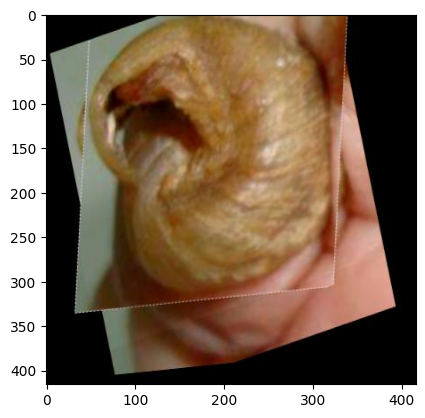

In [70]:
from PIL import Image
img_path = "path"
img = Image.open(img_path)
plt.imshow(img)

In [71]:
model = YOLO("YOLO_WEIGHTS")

img = cv2.imread(img_path)
results = model(img)

print("Number of boxes:", len(results[0].boxes))

crop = np.array([])

for box in results[0].boxes:
    print("Box:", box)

    x1, y1, x2, y2 = map(int, box.xyxy[0])

    crop = img[y1:y2, x1:x2]


0: 640x640 1 Nail, 7.2ms
Speed: 2.0ms preprocess, 7.2ms inference, 1.2ms postprocess per image at shape (1, 3, 640, 640)
Number of boxes: 1
Box: ultralytics.engine.results.Boxes object with attributes:

cls: tensor([0.], device='cuda:0')
conf: tensor([0.8092], device='cuda:0')
data: tensor([[ 49.1288,   0.0000, 337.2061, 319.4506,   0.8092,   0.0000]], device='cuda:0')
id: None
is_track: False
orig_shape: (416, 416)
shape: torch.Size([1, 6])
xywh: tensor([[193.1674, 159.7253, 288.0773, 319.4506]], device='cuda:0')
xywhn: tensor([[0.4643, 0.3840, 0.6925, 0.7679]], device='cuda:0')
xyxy: tensor([[ 49.1288,   0.0000, 337.2061, 319.4506]], device='cuda:0')
xyxyn: tensor([[0.1181, 0.0000, 0.8106, 0.7679]], device='cuda:0')


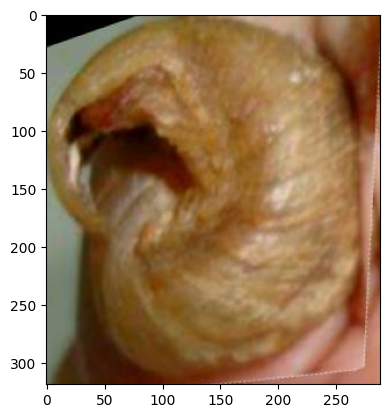

In [72]:
crop = cv2.cvtColor(crop, cv2.COLOR_BGR2RGB)
plt.imshow(crop)